## Question 1 ##

In [19]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [35]:
im = cv.imread('images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

In [45]:
# Parameters
sigma_min = 4
sigma_max = 40
n_scales = 20
sigmas = np.geomspace(sigma_min, sigma_max, n_scales)

scale_space = np.zeros((gray.shape[0], gray.shape[1], n_scales), dtype=np.float32)

for i, s in enumerate(sigmas):
    blurred = cv.GaussianBlur(gray, (0, 0), s)
    lap = cv.Laplacian(blurred, cv.CV_32F)
    scale_space[:, :, i] = (s**2 * lap) ** 2   # Normalized, squared so bright and dark blobs both give peaks

print(scale_space.shape)
print(sigmas.round(2))

(360, 360, 20)
[ 4.    4.52  5.1   5.75  6.5   7.33  8.28  9.34 10.55 11.91 13.44 15.17
 17.13 19.33 21.82 24.63 27.81 31.39 35.43 40.  ]


0.14518465
16 blobs found
16 blobs after suppression
15 blobs after removing border ones
7 blobs at sigma_min


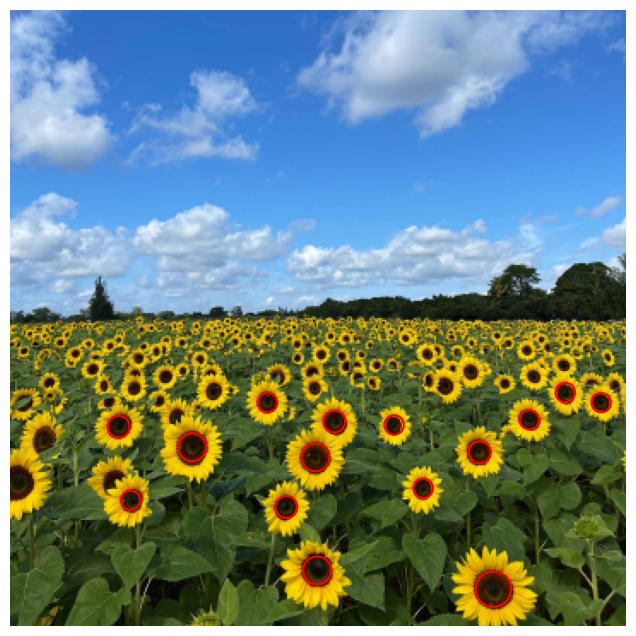

Sigma range used: 4 to 40 (20 scales, geometric)
Largest circles (x, y, radius, sigma):
  x=282, y=338, r=10.4, sigma=7.3
  x=178, y=261, r=8.1, sigma=5.8
  x=179, y=327, r=8.1, sigma=5.8
  x=106, y=255, r=8.1, sigma=5.8
  x=63, y=243, r=6.4, sigma=4.5


In [49]:
from scipy.ndimage import maximum_filter

print(scale_space.max())

# Detect extrema
threshold = 0.63 * scale_space.max()   # Tune: 0.3, 0.4, 0.5
local_max = maximum_filter(scale_space, size=(3, 3, 3)) == scale_space
mask = local_max & (scale_space > threshold)

ys, xs, si = np.where(mask)
radii = np.sqrt(2) * sigmas[si]
print(len(xs), 'blobs found')

# Suppression
responses = scale_space[ys, xs, si]
order = np.argsort(-responses)
keep = []
for i in order:
    ok = True
    for j in keep:
        d = np.hypot(xs[i] - xs[j], ys[i] - ys[j])
        if d < max(radii[i], radii[j]):
            ok = False
            break
    if ok:
        keep.append(i)

keep = np.array(keep)
bx, by, br, bs = xs[keep], ys[keep], radii[keep], sigmas[si[keep]]
print(len(bx), 'blobs after suppression')

# Remove blobs whose circle crosses the border
h, w = gray.shape
inside = (bx - br >= 0) & (bx + br < w) & (by - br >= 0) & (by + br < h)
bx, by, br, bs = bx[inside], by[inside], br[inside], bs[inside]
print(len(bx), 'blobs after removing border ones')
print((bs <= sigmas[0] + 1e-6).sum(), 'blobs at sigma_min')

# Drawing the blobs
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
for x, y, r in zip(bx, by, br):
    ax.add_patch(plt.Circle((x, y), r, color='red', fill=False, linewidth=1.5))
ax.axis('off')
plt.show()

# Report the values
top = np.argsort(-br)[:5]
print('Sigma range used:', sigma_min, 'to', sigma_max, f'({n_scales} scales, geometric)')
print('Largest circles (x, y, radius, sigma):')
for k in top:
    print(f'  x={bx[k]}, y={by[k]}, r={br[k]:.1f}, sigma={bs[k]:.1f}')

*Explanation*

The sunflower image was loaded at quarter resolution (360 × 360), converted to grayscale and normalized to [0, 1]. For each σ, the image was blurred with a Gaussian and the Laplacian was applied, then multiplied by σ² to get the scale-normalized LoG, σ²∇²G. The responses were squared so that bright and dark blobs both give positive peaks. A pixel was accepted as a blob if it was a local maximum in a 3 × 3 × 3 neighbourhood (y, x, σ) and above a threshold. Overlapping detections were suppressed by keeping the strongest one, and blobs whose circles crossed the image boundary were removed. Each blob is drawn as a circle of radius r = √2 σ.

**Parameters**
- **Scale range:** σ = 4 to 40, using 20 geometrically spaced values.
- **Threshold:** 0.63 × maximum response (≈ 0.094).
- **Neighbourhood:** 3 × 3 × 3.
- **Circle radius:** r = √2 σ.

**Results** \
The detector found 16 candidates, 16 after overlap suppression and 15 after removing boundary blobs. The largest circles are listed below (coordinates in the quarter-size image).

| x (px) | y (px) | Radius (px) | σ |
|---:|---:|---:|---:|
| 282 | 338 | 10.4 | 7.3 |
| 178 | 261 | 8.1 | 5.8 |
| 179 | 327 | 8.1 | 5.8 |

**Discussion** \
At this threshold, the detections lie on sunflower heads. The largest detected scale (σ = 7.3) was well below σ_max = 40, so the upper limit was not restrictive. 7 of the 15 detections sit at σ_min = 4, so some small flowers may be clipped by the lower end of the range. A threshold of 0.2 gave 111 blobs, many on leaf texture and image borders. At 0.4, detections still appeared on tree clumps behind the field (including the two largest circles, r = 19.0 and 16.8), so I raised it to 0.63. This removes the tree detections but also misses fainter or more distant flowers, so there is a trade-off between false detections and missed flowers.

## Question 2 ##